# code_166 · An ordered sensor stream with delayed labels and retention

**Book:** section 31.6. A self-contained limited-label learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_31_GUIDE.md), [run evidence](../CHAPTER_31_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_166).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=4266;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 4266


<a id="ordered-stream-and-feedback"></a>
 ## Predict before the outcome enters training
 Generate 360 ordered building events,120 per sensor generation. Sensor coordinates rotate between generations; generation metadata is observed. A third outcome class first appears in generation 2. A three-logit head is explicitly preallocated, but no class 2 label exists in the initial data. The first 30 events supply a common warm-up fit; the next 330 events are predicted before feedback arrives five events later. Compare naive updates, a 64-record reservoir replay buffer, diagonal empirical-Fisher parameter regularization and periodic full refitting from the same random initialization. Incremental methods take five Adam steps per newly delivered label; periodic refitting takes 200 full-batch steps every 40 delivered labels. All settings are fixed without a development search. Separate generated held-out building sets assess retention only after their generation has arrived; future cells remain unreported.


,method,prequential_generation0_accuracy,prequential_generation1_accuracy,prequential_generation2_accuracy,final_mean_retention_accuracy,generation0_forgetting_from_best,gradient_updates_after_warmup,processed_examples_after_warmup,peak_retained_labelled_records
0,Naive,1.0,0.966667,0.866667,0.329630,1.0,1625,1625,0
1,Replay,1.0,0.966667,0.716667,1.000000,0.0,1625,27625,64
2,Regularized,1.0,0.966667,0.875000,0.366667,1.0,1625,1625,64
3,Periodic refit,1.0,0.908333,0.708333,1.000000,0.0,1600,336000,355


First delayed feedback: [{'prediction_event': 35, 'feedback_event_admitted': 30, 'delay': 5}, {'prediction_event': 36, 'feedback_event_admitted': 31, 'delay': 5}, {'prediction_event': 37, 'feedback_event_admitted': 32, 'delay': 5}, {'prediction_event': 38, 'feedback_event_admitted': 33, 'delay': 5}, {'prediction_event': 39, 'feedback_event_admitted': 34, 'delay': 5}]


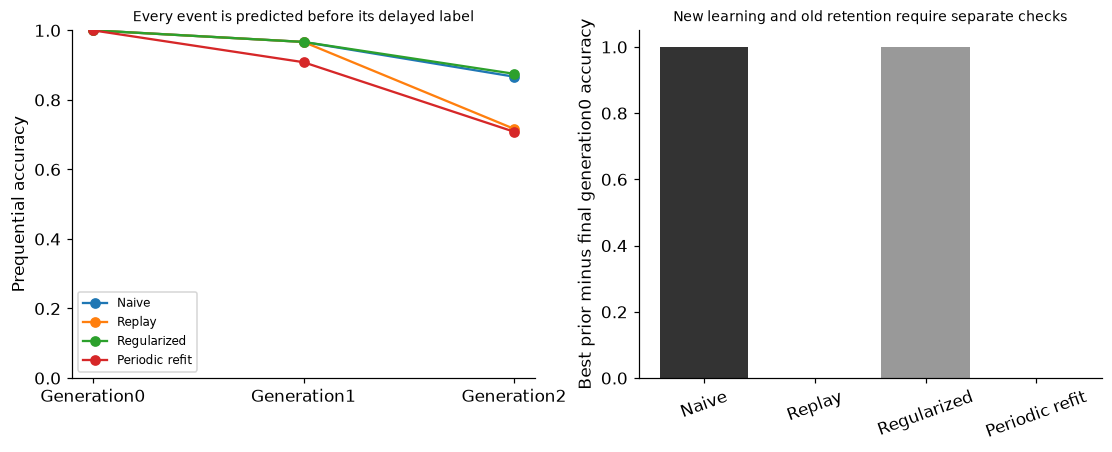

In [2]:
def generation_data(g,n,generator):
    label=generator.integers(0,2 if g<2 else 3,n);centres=np.array([[-1.,0.],[1.,0.],[0.,1.7]]);canonical=centres[label]+generator.normal(0,.28,(n,2));angle=[0,np.pi/2,np.pi][g];rotation=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]]);sensor=canonical@rotation.T;return np.column_stack([sensor,np.full(n,g/2)]),label
stream_x=[];stream_y=[];tests=[]
for g in range(3):
    x,y=generation_data(g,120,rng);stream_x.extend(x);stream_y.extend(y);tests.append(generation_data(g,90,rng))
X=torch.tensor(np.array(stream_x));Y=torch.tensor(np.array(stream_y));assert not torch.any(Y[:240]==2) and torch.any(Y[240:]==2)
def network():return nn.Sequential(nn.Linear(3,16),nn.Tanh(),nn.Linear(16,3))
torch.manual_seed(SEED);warm=network();random_state=copy.deepcopy(warm.state_dict());optimizer=torch.optim.Adam(warm.parameters(),lr=.02)
for _ in range(200):optimizer.zero_grad();loss=nn.functional.cross_entropy(warm(X[:30]),Y[:30]);loss.backward();optimizer.step()
names=['Naive','Replay','Regularized','Periodic refit'];models={name:copy.deepcopy(warm) for name in names};optimizers={name:torch.optim.Adam(models[name].parameters(),lr=.02) for name in names if name!='Periodic refit'};predictions={name:[] for name in names};retention={name:np.full((3,3),np.nan) for name in names};counts={name:{'gradient_updates_after_warmup':0,'processed_examples_after_warmup':0,'peak_retained_labelled_records':0} for name in names};archive=list(range(30));buffer=list(range(30));phase_buffer=list(range(30));last_feedback_generation=0;seen=30;replay_rng=np.random.default_rng(SEED+8);regularization_strength=50.;importance={n:torch.zeros_like(p) for n,p in models['Regularized'].named_parameters()};anchor={n:p.detach().clone() for n,p in models['Regularized'].named_parameters()};event_audit=[];fisher_evaluations=[0]
def consolidate():
    model=models['Regularized'];fresh={n:torch.zeros_like(p) for n,p in model.named_parameters()}
    for i in phase_buffer:
        fisher_evaluations[0]+=1
        logp=nn.functional.log_softmax(model(X[i:i+1]),dim=1)[0,Y[i]];grads=torch.autograd.grad(logp,list(model.parameters()))
        for (n,p),grad in zip(model.named_parameters(),grads):fresh[n]+=grad.detach().square()/len(phase_buffer)
    for n,p in model.named_parameters():importance[n]=.9*importance[n]+fresh[n];anchor[n]=p.detach().clone()
for tick in range(30,360):
    for name,model in models.items():
        with torch.no_grad():predictions[name].append(int(model(X[tick:tick+1]).argmax(1)))
    delivered=tick-5
    if delivered>=30:
        assert delivered<tick;g=delivered//120
        if g!=last_feedback_generation:consolidate();phase_buffer=[];last_feedback_generation=g
        for name in ['Naive','Replay','Regularized']:
            model=models[name];opt=optimizers[name]
            if name=='Replay':ids=[delivered]+replay_rng.choice(buffer,min(16,len(buffer)),replace=False).tolist()
            else:ids=[delivered]
            assert max(ids)<=tick-5
            for _ in range(5):
                loss=nn.functional.cross_entropy(model(X[ids]),Y[ids])
                if name=='Regularized':loss=loss+regularization_strength/2*sum((importance[n]*(p-anchor[n]).square()).sum() for n,p in model.named_parameters())
                opt.zero_grad();loss.backward();opt.step();counts[name]['gradient_updates_after_warmup']+=1;counts[name]['processed_examples_after_warmup']+=len(ids)
        seen+=1
        if len(buffer)<64:buffer.append(delivered)
        else:
            j=int(replay_rng.integers(seen))
            if j<64:buffer[j]=delivered
        phase_buffer.append(delivered);phase_buffer=phase_buffer[-64:];archive.append(delivered);counts['Replay']['peak_retained_labelled_records']=max(counts['Replay']['peak_retained_labelled_records'],len(buffer));counts['Regularized']['peak_retained_labelled_records']=max(counts['Regularized']['peak_retained_labelled_records'],len(phase_buffer));counts['Periodic refit']['peak_retained_labelled_records']=len(archive)
        if (len(archive)-30)%40==0:
            model=network();model.load_state_dict(random_state);opt=torch.optim.Adam(model.parameters(),lr=.02)
            for _ in range(200):opt.zero_grad();loss=nn.functional.cross_entropy(model(X[archive]),Y[archive]);loss.backward();opt.step()
            models['Periodic refit']=model;counts['Periodic refit']['gradient_updates_after_warmup']+=200;counts['Periodic refit']['processed_examples_after_warmup']+=200*len(archive)
        if len(event_audit)<5:event_audit.append({'prediction_event':tick,'feedback_event_admitted':delivered,'delay':tick-delivered})
    if tick in [119,239,359]:
        stage=tick//120
        for name,model in models.items():
            for test_generation in range(stage+1):
                tx,ty=tests[test_generation]
                with torch.no_grad():pred=model(torch.tensor(tx)).argmax(1).numpy()
                retention[name][stage,test_generation]=np.mean(pred==ty)
assert len(archive)==355 and len(buffer)==64 and max(buffer)<=354 and len(phase_buffer)<=64
rows=[]
for name in names:
    pred=np.array(predictions[name]);truth=Y[30:].numpy();phase=np.arange(30,360)//120;matrix=retention[name];forgetting=float(np.max(matrix[:,0])-matrix[-1,0]);rows.append({'method':name,'prequential_generation0_accuracy':float(np.mean(pred[phase==0]==truth[phase==0])),'prequential_generation1_accuracy':float(np.mean(pred[phase==1]==truth[phase==1])),'prequential_generation2_accuracy':float(np.mean(pred[phase==2]==truth[phase==2])),'final_mean_retention_accuracy':float(matrix[-1].mean()),'generation0_forgetting_from_best':forgetting,**counts[name]})
matrices={name:[[None if not np.isfinite(v) else float(v) for v in row] for row in matrix] for name,matrix in retention.items()};RESULTS.update(stream_events=360,warmup_observed_labels=30,warmup_updates=200,warmup_processed_examples=6000,predictions_before_feedback=330,feedback_delay_events=5,last_five_labels_unadmitted=5,final_admitted_labels=355,preallocated_classes=3,first_class2_generation=2,replay_capacity=64,regularization_strength=regularization_strength,importance_labelled_gradient_evaluations=fisher_evaluations[0],regularization_parameter_snapshots=2*sum(p.numel() for p in warm.parameters()),periodic_refit_every_delivered_labels=40,periodic_refit_updates=200,metrics=rows,retention_matrices=matrices,first_feedback_audit=event_audit,future_generation_retention_cells_reported=False);display(pd.DataFrame(rows));print('First delayed feedback:',event_audit)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for row in rows:axes[0].plot(range(3),[row[f'prequential_generation{g}_accuracy'] for g in range(3)],marker='o',label=row['method'])
axes[0].set(xticks=range(3),xticklabels=['Generation0','Generation1','Generation2'],ylim=(0,1),ylabel='Prequential accuracy',title='Every event is predicted before its delayed label');axes[0].legend(fontsize=8);axes[1].bar(range(4),[r['generation0_forgetting_from_best'] for r in rows],color=['.2','.4','.6','.8']);axes[1].set(xticks=range(4),xticklabels=names,ylabel='Best prior minus final generation0 accuracy',title='New learning and old retention require separate checks');axes[1].tick_params(axis='x',rotation=20);plt.show()


<a id="retention-and-resource-boundaries"></a>
 ## A periodic full refit is not an online parameter update
 The periodic comparator restarts from the same random initialization and fits all labels admitted by that tick; it stores an expanding archive and consumes many more labelled-example passes. Incremental methods update existing weights. Reservoir replay keeps at most 64 raw records; parameter regularization keeps a bounded current-generation sample plus a diagonal importance and anchor vector. Its empirical-Fisher penalty is an explicit EWC-style mechanism, not a replication of the original benchmark or a guarantee against forgetting. Known sensor-generation metadata provides boundary information for consolidation. The last five stream labels never reach a learner before the stream ends; their predictions are scored retrospectively only. Held-out retention sets are disjoint from all stream records, and future-generation matrix cells stay absent until the generation arrives. No retention score selects a policy or checkpoint.


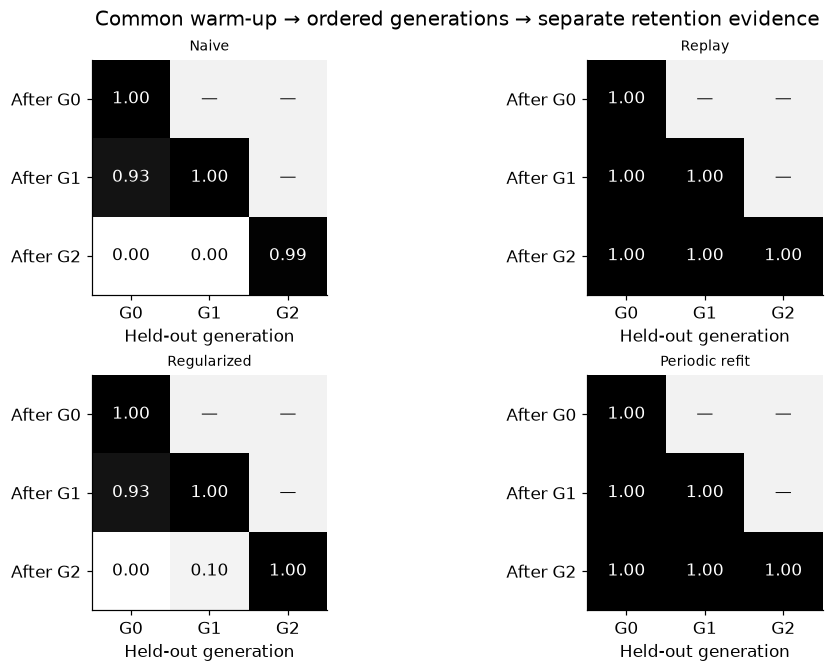

In [3]:
fig,axes=plt.subplots(2,2,figsize=(9,6));cmap=plt.get_cmap('Greys').copy();cmap.set_bad('.95')
for ax,name in zip(axes.flat,names):
    matrix=retention[name];ax.imshow(np.ma.masked_invalid(matrix),vmin=0,vmax=1,cmap=cmap);ax.set(xticks=range(3),yticks=range(3),xticklabels=['G0','G1','G2'],yticklabels=['After G0','After G1','After G2'],xlabel='Held-out generation',title=name)
    for (i,j),value in np.ndenumerate(matrix):ax.text(j,i,'—' if not np.isfinite(value) else f'{value:.2f}',ha='center',va='center',color='white' if np.isfinite(value) and value>.5 else 'black')
fig.suptitle('Common warm-up → ordered generations → separate retention evidence');plt.show()
assert len(rows)==4 and all(len(p)==330 for p in predictions.values()) and all(matrix[0,1:].shape==(2,) and np.isnan(matrix[0,1:]).all() for matrix in retention.values())


In [4]:
summary={'example_id':'code_166','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual prequential predictions before five-event-delayed feedback', 'naive online bounded reservoir replay EWC-style regularization and periodic full refit', 'three ordered sensor generations with a newly observed third class', 'retention matrices restricted to already arrived generations', 'raw-record storage gradient updates and processed-example budgets measured'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual prequential predictions before five-event-delayed feedback", "naive online bounded reservoir replay EWC-style regularization and periodic full refit", "three ordered sensor generations with a newly observed third class", "retention matrices restricted to already arrived generations", "raw-record storage gradient updates and processed-example budgets measured"], "elapsed_seconds": 1.692, "example_id": "code_166", "hardware": "Darwin arm64 CPU", "results": {"feedback_delay_events": 5, "final_admitted_labels": 355, "first_class2_generation": 2, "first_feedback_audit": [{"delay": 5, "feedback_event_admitted": 30, "prediction_event": 35}, {"delay": 5, "feedback_event_admitted": 31, "prediction_event": 36}, {"delay": 5, "feedback_event_admitted": 32, "prediction_event": 37}, {"delay": 5, "feedback_event_admitted": 33, "prediction_event": 38}, {"delay": 5, "feedback_event_admitted": 34, "prediction_event": 39}], "future_generation_rete